### Common libraries and `mpl` settings

In [2]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from cmcrameri import cm as cmc

MM = 1.0 / 25.4

mpl.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.fallback": "stix",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "legend.frameon": False,
        "axes.grid": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

out_folder = Path("figures")
out_folder.mkdir(exist_ok=True)

alphas = (100, 200, 400, 800)
colors = dict(zip(alphas, cmc.batlow(np.linspace(0.15, 0.85, len(alphas)))))

## Data preparation from MD
Read the 80 two-fibre calculations form `two_fiber/heat/results/`. Store all individual target energy histories, initial target temperatures, final energies and geometric estimates.

In [6]:
root = Path("../two_fiber/heat/results/TMB")
if not root.is_dir():
    raise FileNotFoundError(root)

pp = Path("pp_data")
pp.mkdir(exist_ok=True)
series = {
    f"s{s}+s{s + 1}": sorted(
        path
        for path in root.glob(f"gap*_s{s}s{s + 1}/alpha_*")
        if path.is_dir()
        and re.fullmatch(rf"gap\d+_s{s}s{s + 1}", path.parent.name)
        and re.fullmatch(r"alpha_\d+(?:\.\d+)?", path.name)
    )
    for s in range(42, 52, 2)
}

R_fiber = 16 * 3.144 / 10
p = 0.06
HeV = 2
rows = []
curve_rows = []

for name, paths in series.items():
    for path in paths:
        if not all(
            (path / f).exists()
            for f in (
                "initial_state.txt",
                "impact.txt",
                "heat.txt",
                "heat_off.txt",
                "log.lammps",
            )
        ):
            continue

        alpha = float(path.name.removeprefix("alpha_"))
        if alpha not in alphas:
            continue

        gap = int(re.search(r"gap(\d+)", path.parent.name).group(1)) / 10
        ini = pd.read_csv(path / "initial_state.txt", sep=r"\s+").iloc[0]
        impact = pd.read_csv(path / "impact.txt", sep=r"\s+", comment="#")
        end = impact.iloc[-1]
        off = pd.read_csv(path / "heat_off.txt", sep=r"\s+")
        tc = float(off.loc[off.stage.eq("break"), "time_ps"].iloc[0])

        log = (path / "log.lammps").read_text(errors="replace")
        N_source_W = int(re.search(r"(\d+)\s+atoms in group source_W", log).group(1))
        chi_He = p / (1 - p) * HeV
        eps_fit = (
            5.99425913 + 0.58854966 * alpha / 400 - 1.64798361 * p - 1.09844705 * chi_He
        )
        f_geom = np.arcsin(R_fiber / (2 * R_fiber + gap)) / np.pi

        E0 = ini.K_targetW_eV + ini.U_targetW_eV
        E_MD = (end.K_targetW_eV + end.U_targetW_eV - E0) / 1000
        rows.append(
            (
                name,
                alpha,
                gap,
                tc,
                E_MD,
                N_source_W * eps_fit * f_geom / 1000,
                ini.T_target,
            )
        )

        heat = pd.read_csv(path / "heat.txt", sep=r"\s+")
        z = (
            pd.concat([heat, impact])
            .sort_values("time_ps")
            .drop_duplicates("time_ps", keep="last")
        )
        z = z.loc[z.time_ps.between(tc - 200, tc + 1000)]
        E = (z.K_targetW_eV + z.U_targetW_eV - E0) / 1000
        curve_rows.extend(
            (name, alpha, gap, t - tc, e, T)
            for t, e, T in zip(z.time_ps, E, z.T_target)
        )

main = pd.DataFrame(
    rows,
    columns=["series", "alpha", "gap_nm", "tc", "E_MD_keV", "E_fit_keV", "T0_target_K"],
)
main = main.sort_values(["alpha", "gap_nm", "series"]).reset_index(drop=True)
curves = pd.DataFrame(
    curve_rows,
    columns=["series", "alpha", "gap_nm", "time_rel_ps", "E_target_keV", "T_target_K"],
)
assert len(main) == 80, f"Expected 80 cases, found {len(main)}"
assert curves.groupby(["series", "gap_nm", "alpha"]).ngroups == 80
main.to_csv(pp / "two_fiber_summary.csv", index=False)
curves.to_csv(pp / "two_fiber_energy_curves.csv.gz", index=False, compression="gzip")
print(f"Two-fibre trajectories: {len(main)}, curve records: {len(curves)}")

Two-fibre trajectories: 80, curve records: 97173


## Figures from processed data
The following cells require only the exported files in `pp_data/`.

In [7]:
main = pd.read_csv("pp_data/two_fiber_summary.csv")
assert len(main) == 80
print(f"Calculations: {len(main)}")
print(main.groupby(["series", "alpha"]).size().unstack(fill_value=0))

Calculations: 80
alpha    100.0  200.0  400.0  800.0
series                             
s42+s43      4      4      4      4
s44+s45      4      4      4      4
s46+s47      4      4      4      4
s48+s49      4      4      4      4
s50+s51      4      4      4      4


### Figure 10 — time-resolved target energy

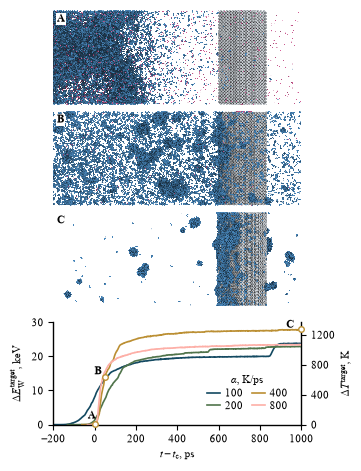

 alpha  dE_keV    dT_K  scale
   100   23.77 1091.69  45.93
   200   22.83 1054.34  46.18
   400   27.98 1248.15  44.60
   800   23.45 1077.96  45.98

Mean fitted scale = 45.565 K/keV


In [48]:
gap = 30
times = [0, 50, 1000]
snap_folder = Path("figures/energy_transfer_snapshots")

energy_curves = pd.read_csv("pp_data/two_fiber_energy_curves.csv.gz")
selected = main.loc[main.series.eq("s42+s43") & main.gap_nm.eq(gap)].sort_values(
    "alpha"
)

width = 85
left = 11
right = 11
bottom = 8
top = 2
vspace = 1.5
gap_to_graph = 4.0
graph_height = 26

imgs = []
for tau in times:
    img = plt.imread(snap_folder / f"energy_transfer_t{tau:03d}.png")
    img = img[90:710, int(0.19 * img.shape[1]) :]
    imgs.append(img)

panel_width = width - left - right
snap_height = panel_width * imgs[0].shape[0] / imgs[0].shape[1]
height = top + 3 * snap_height + 2 * vspace + gap_to_graph + graph_height + bottom

fig_transfer = plt.figure(figsize=(width * MM, height * MM))

for i, img in enumerate(imgs):
    y = height - top - (i + 1) * snap_height - i * vspace
    ax_img = fig_transfer.add_axes(
        [left / width, y / height, panel_width / width, snap_height / height]
    )
    ax_img.imshow(img, interpolation="none")
    ax_img.text(
        0.015,
        0.96,
        chr(65 + i),
        transform=ax_img.transAxes,
        ha="left",
        va="top",
        fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", pad=0.5),
    )
    ax_img.axis("off")

ax = fig_transfer.add_axes(
    [left / width, bottom / height, panel_width / width, graph_height / height]
)

ends = []
for r in selected.itertuples():
    z = energy_curves.loc[
        energy_curves.series.eq(r.series)
        & energy_curves.gap_nm.eq(r.gap_nm)
        & energy_curves.alpha.eq(r.alpha)
    ].sort_values("time_rel_ps")

    t = z.time_rel_ps.to_numpy()
    E = z.E_target_keV.to_numpy()
    dT = z.T_target_K.iloc[-1] - r.T0_target_K
    alpha = int(r.alpha)

    ends.append((alpha, E[-1], dT))
    ax.plot(t, E, color=colors[alpha], lw=1.2, label=str(alpha))

ends = pd.DataFrame(ends, columns=["alpha", "dE_keV", "dT_K"])
scale = np.dot(ends.dE_keV, ends.dT_K) / np.dot(ends.dE_keV, ends.dE_keV)

ax.set(
    xlim=(-200, 1000),
    ylim=(0, 30),
    yticks=[0, 10, 20, 30],
    xlabel=r"$t-t_{\mathrm{c}}$, ps",
    ylabel=r"$\Delta E_{\mathrm{W}}^{\mathrm{target}}$, keV",
)

ax.legend(
    title=r"$\alpha$, K/ps",
    loc="lower right",
    bbox_to_anchor=(0.985, 0.03),
    ncol=2,
    handlelength=1.2,
    handletextpad=0.4,
    columnspacing=0.8,
    labelspacing=0.2,
    frameon=False,
)

ax2 = ax.secondary_yaxis("right", functions=(lambda E: scale * E, lambda T: T / scale))
ax2.set_ylabel(r"$\Delta T^{\mathrm{target}}$, K")
ax2.set_yticks([0, 400, 800, 1200])

d = energy_curves.loc[
    energy_curves.series.eq("s42+s43")
    & energy_curves.gap_nm.eq(gap)
    & energy_curves.alpha.eq(400)
].sort_values("time_rel_ps")

offsets = [(-2, 6), (-5, 4), (-8, 3)]

for i, (tau, offset) in enumerate(zip(times, offsets)):
    E = np.interp(tau, d.time_rel_ps, d.E_target_keV)

    ax.scatter(
        tau,
        E,
        s=16,
        facecolor="white",
        edgecolor=colors[400],
        linewidth=1,
        zorder=5,
        clip_on=False,
    )

    ax.annotate(
        chr(65 + i),
        (tau, E),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        va="center",
        fontweight="bold",
        zorder=6,
    )

plt.show()

ends["scale"] = ends.dT_K / ends.dE_keV
print(ends.round(2).to_string(index=False))
print(f"\nMean fitted scale = {scale:.3f} K/keV")
fig_transfer.savefig(
    out_folder / "two_fiber_energy_evolution.pdf", dpi=600, pad_inches=0.05
)

### Figure 11 — comparison with the geometric estimate

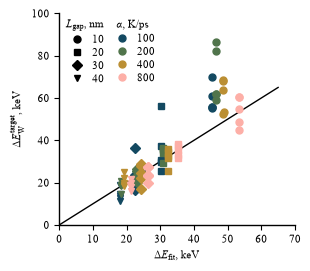

In [8]:
markers = {
    10: "o",
    20: "s",
    30: "D",
    40: "v",
}

fig_energy, ax = plt.subplots(figsize=(80 * MM, 70 * MM))

for r in main.itertuples():
    ax.plot(
        r.E_fit_keV,
        r.E_MD_keV,
        marker=markers[int(r.gap_nm)],
        ls="",
        ms=5,
        markerfacecolor=colors[int(r.alpha)],
        markeredgecolor=colors[int(r.alpha)],
        markeredgewidth=1,
        zorder=3,
    )

ax.plot([0, 65], [0, 65], color="0", lw=1)

ax.set(
    xlim=(0, 70),
    ylim=(0, 100),
    xlabel=r"$\Delta E_{\mathrm{fit}}$, keV",
    ylabel=r"$\Delta E^\mathrm{target}_{\mathrm{W}}$, keV",
)

alpha_handles = [
    Line2D([], [], marker="o", ls="", color=colors[a], ms=5, label=str(a))
    for a in alphas
]

gap_handles = [
    Line2D([], [], marker=markers[g], ls="", color="0", ms=5, label=str(g))
    for g in markers
]

leg = ax.legend(
    handles=alpha_handles,
    title=r"$\alpha$, K/ps",
    loc="upper left",
    bbox_to_anchor=(0.20, 0.99),
    borderaxespad=0,
    labelspacing=0.25,
    handletextpad=0.35,
)
ax.add_artist(leg)

ax.legend(
    handles=gap_handles,
    title=r"$L_{\mathrm{gap}}$, nm",
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    borderaxespad=0,
    labelspacing=0.25,
    handletextpad=0.35,
)

fig_energy.tight_layout()
plt.show()
fig_energy.savefig(out_folder / "two_fiber_energy_comparison.pdf", pad_inches=0.05)